### Cross-Correlation Analysis
Cross-correlation analysis determines not only if a feature is correlated with the target, but also identifies the specific time lag at which this correlation occurs.

In [4]:
import pandas as pd
from utils.paths import DATASETS_PREPROCESSED_DIR

df = pd.read_csv(DATASETS_PREPROCESSED_DIR / "Location_1_train.csv")
df.head()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,wind_speed_10m,wind_speed_100m,wind_gusts_10m,wind_sin_10m,wind_cos_10m,wind_sin_100m,wind_cos_100m,p_base,delta_p
0,2017-01-02 00:00:00,0.395392,0.817073,0.445396,0.0,0.000000,0.032143,0.559193,-0.829038,0.309017,-0.951057,0.005159,-0.005159
1,2017-01-02 01:00:00,0.394470,0.829268,0.447537,0.0,0.085413,0.139286,0.484810,-0.874620,0.374607,-0.927184,0.164120,-0.021720
2,2017-01-02 02:00:00,0.379724,0.890244,0.445396,0.0,0.000000,0.096429,0.529919,-0.848048,0.500000,-0.866025,0.005159,-0.005159
3,2017-01-02 03:00:00,0.385253,0.853659,0.443255,0.0,0.000000,0.039286,0.848048,0.529919,0.965926,-0.258819,0.005159,-0.005159
4,2017-01-02 04:00:00,0.384332,0.853659,0.441113,0.0,0.127639,0.125000,0.848048,0.529919,0.994522,0.104528,0.184905,-0.105605


h=1h: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'wind_speed_10m', 'wind_speed_100m', 'wind_gusts_10m', 'p_base']


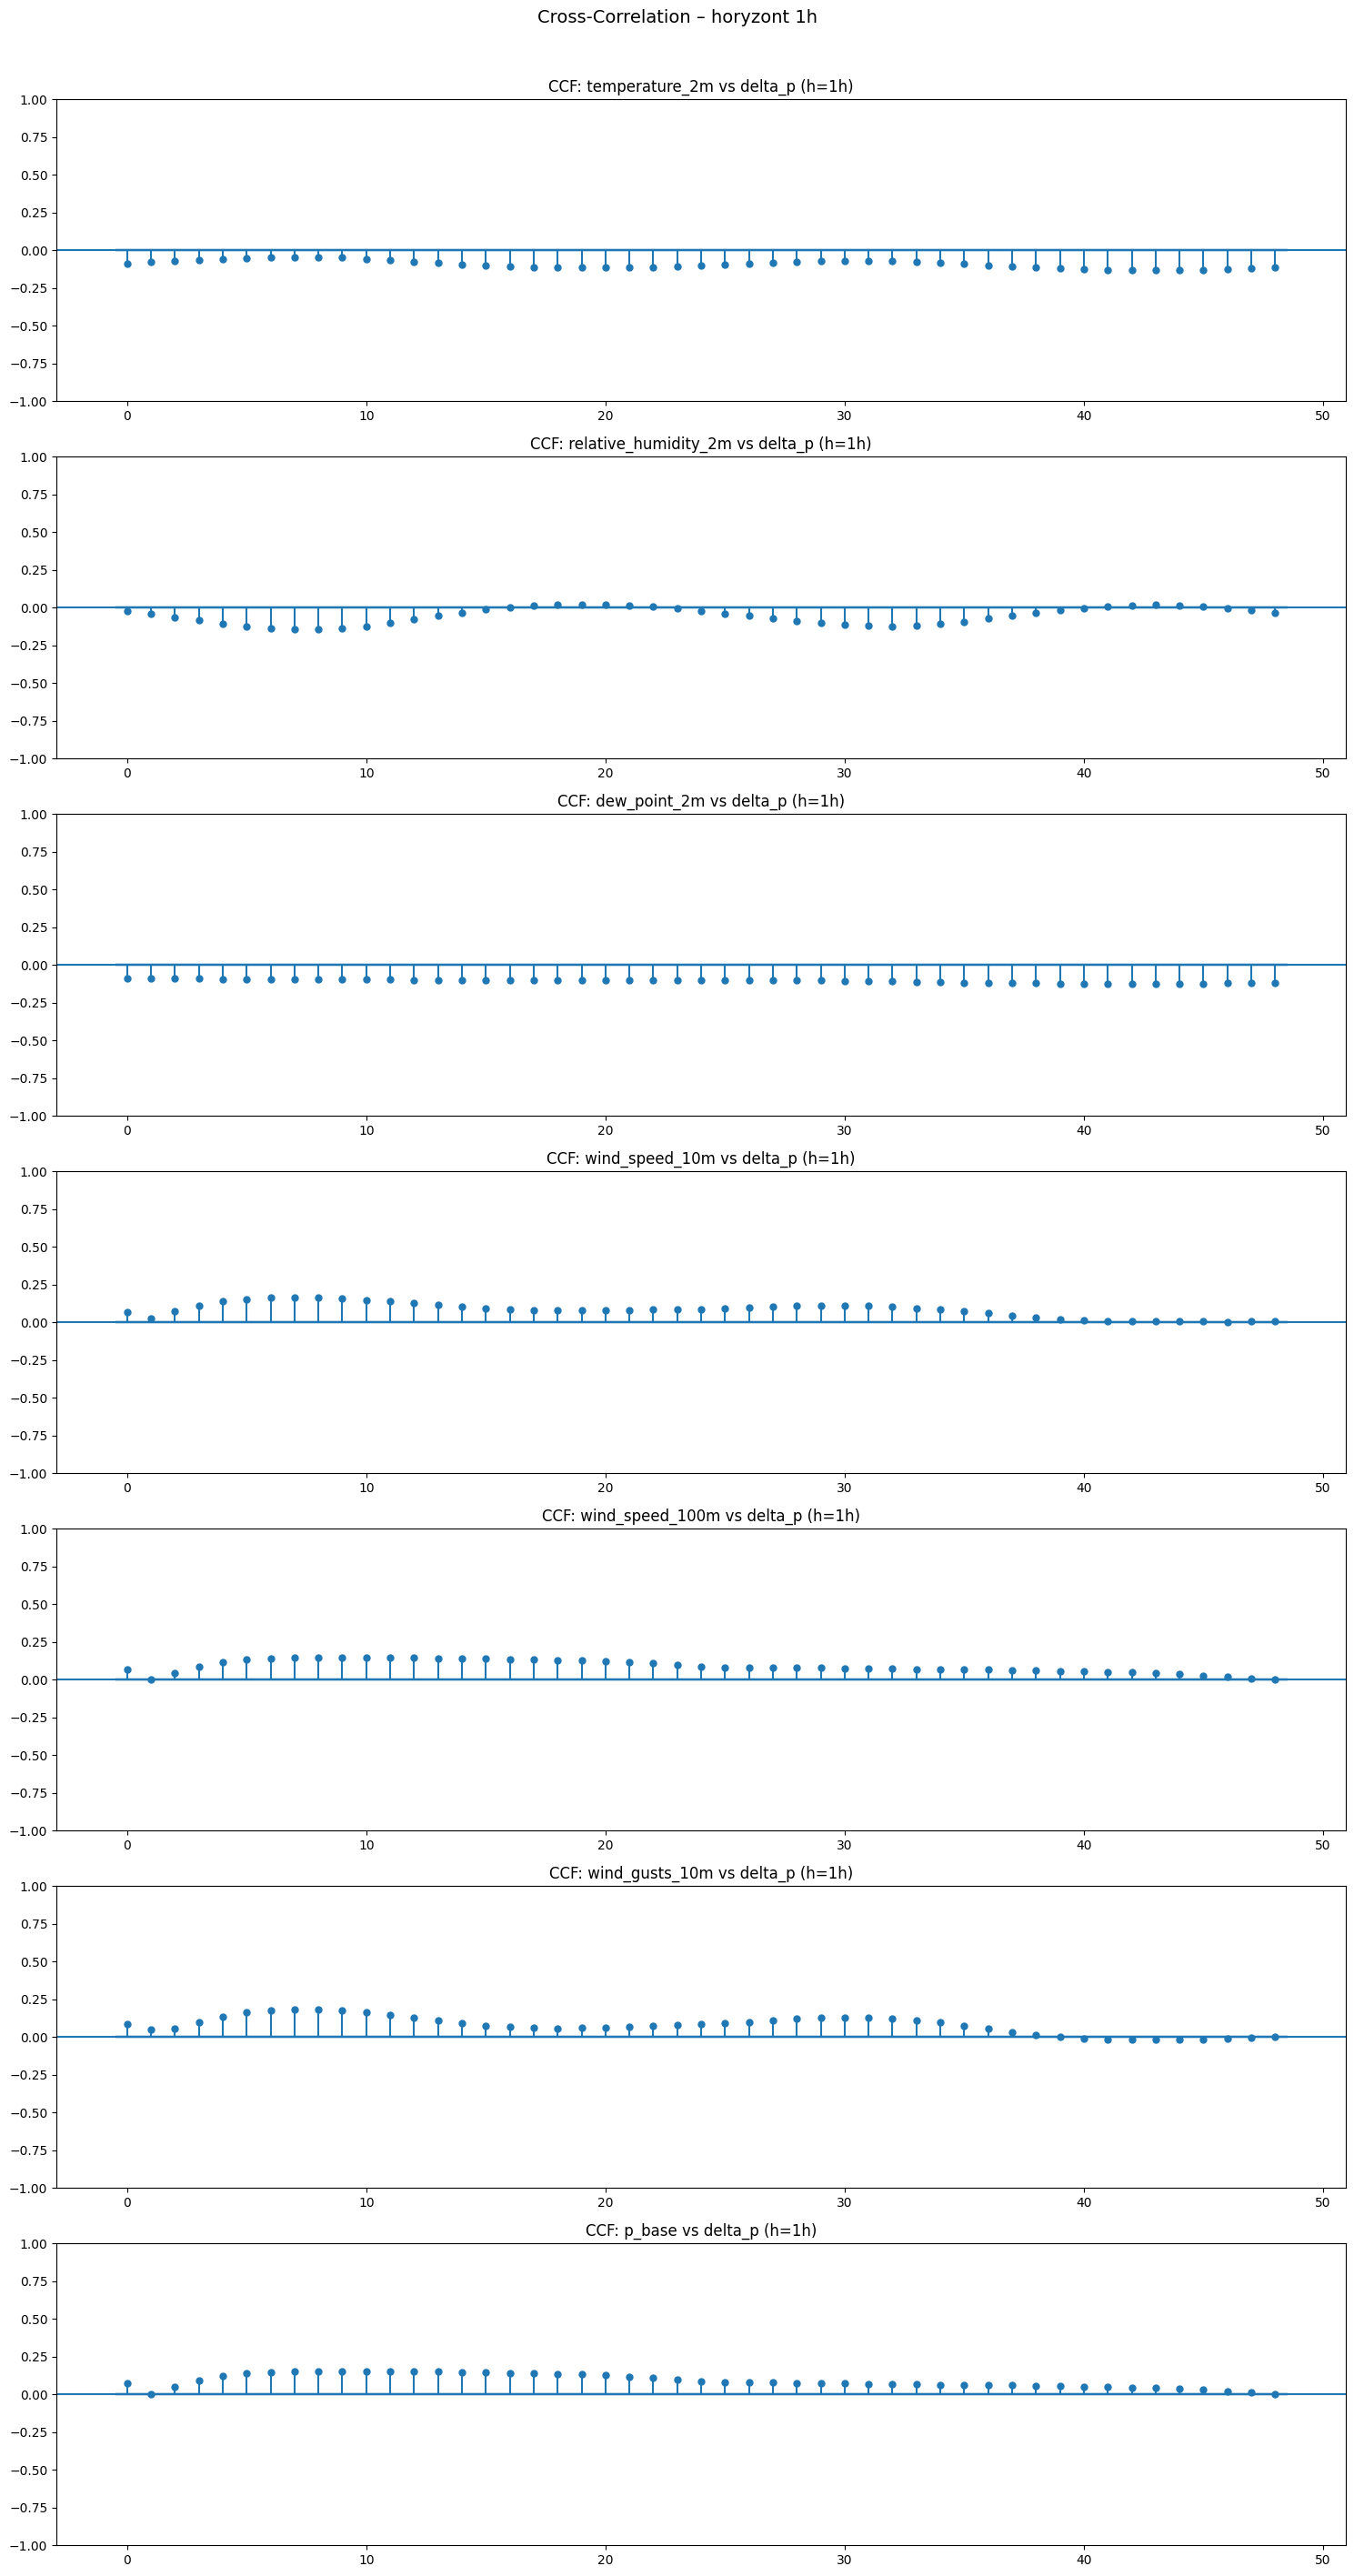

h=24h: ['temperature_2m', 'relative_humidity_2m', 'dew_point_2m', 'wind_speed_10m', 'wind_speed_100m', 'wind_gusts_10m', 'p_base']


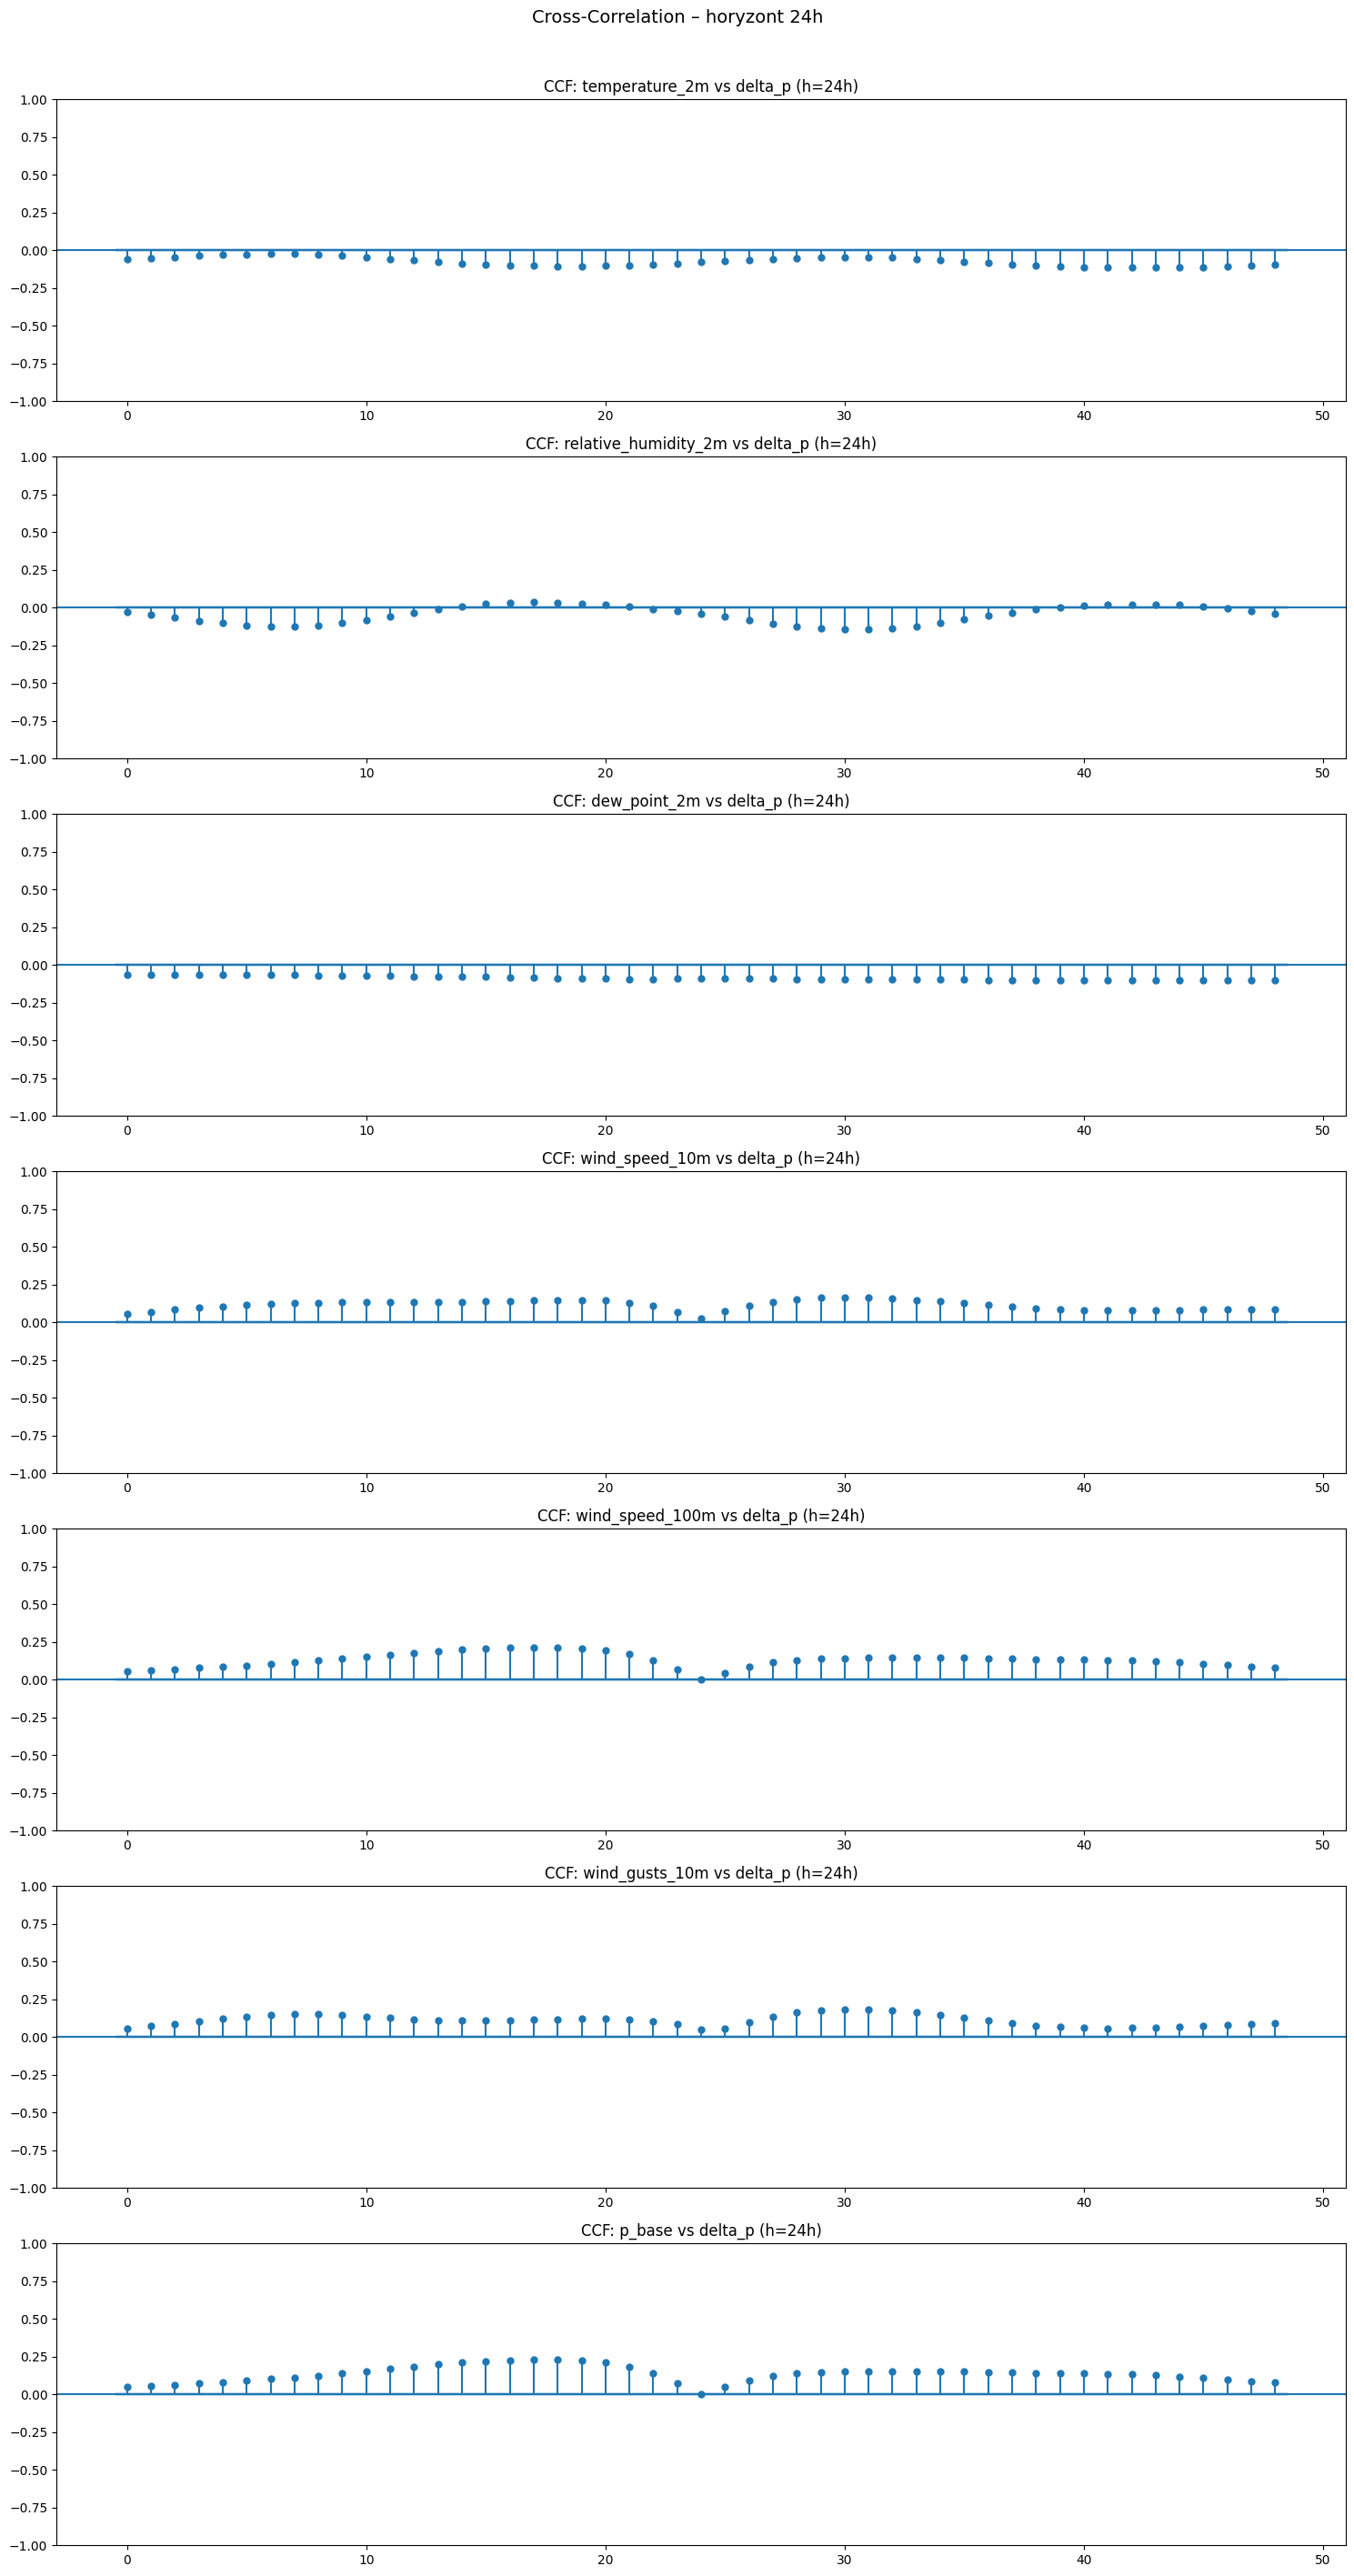

h=48h: ['temperature_2m', 'relative_humidity_2m', 'wind_speed_10m', 'wind_speed_100m', 'wind_gusts_10m', 'p_base']


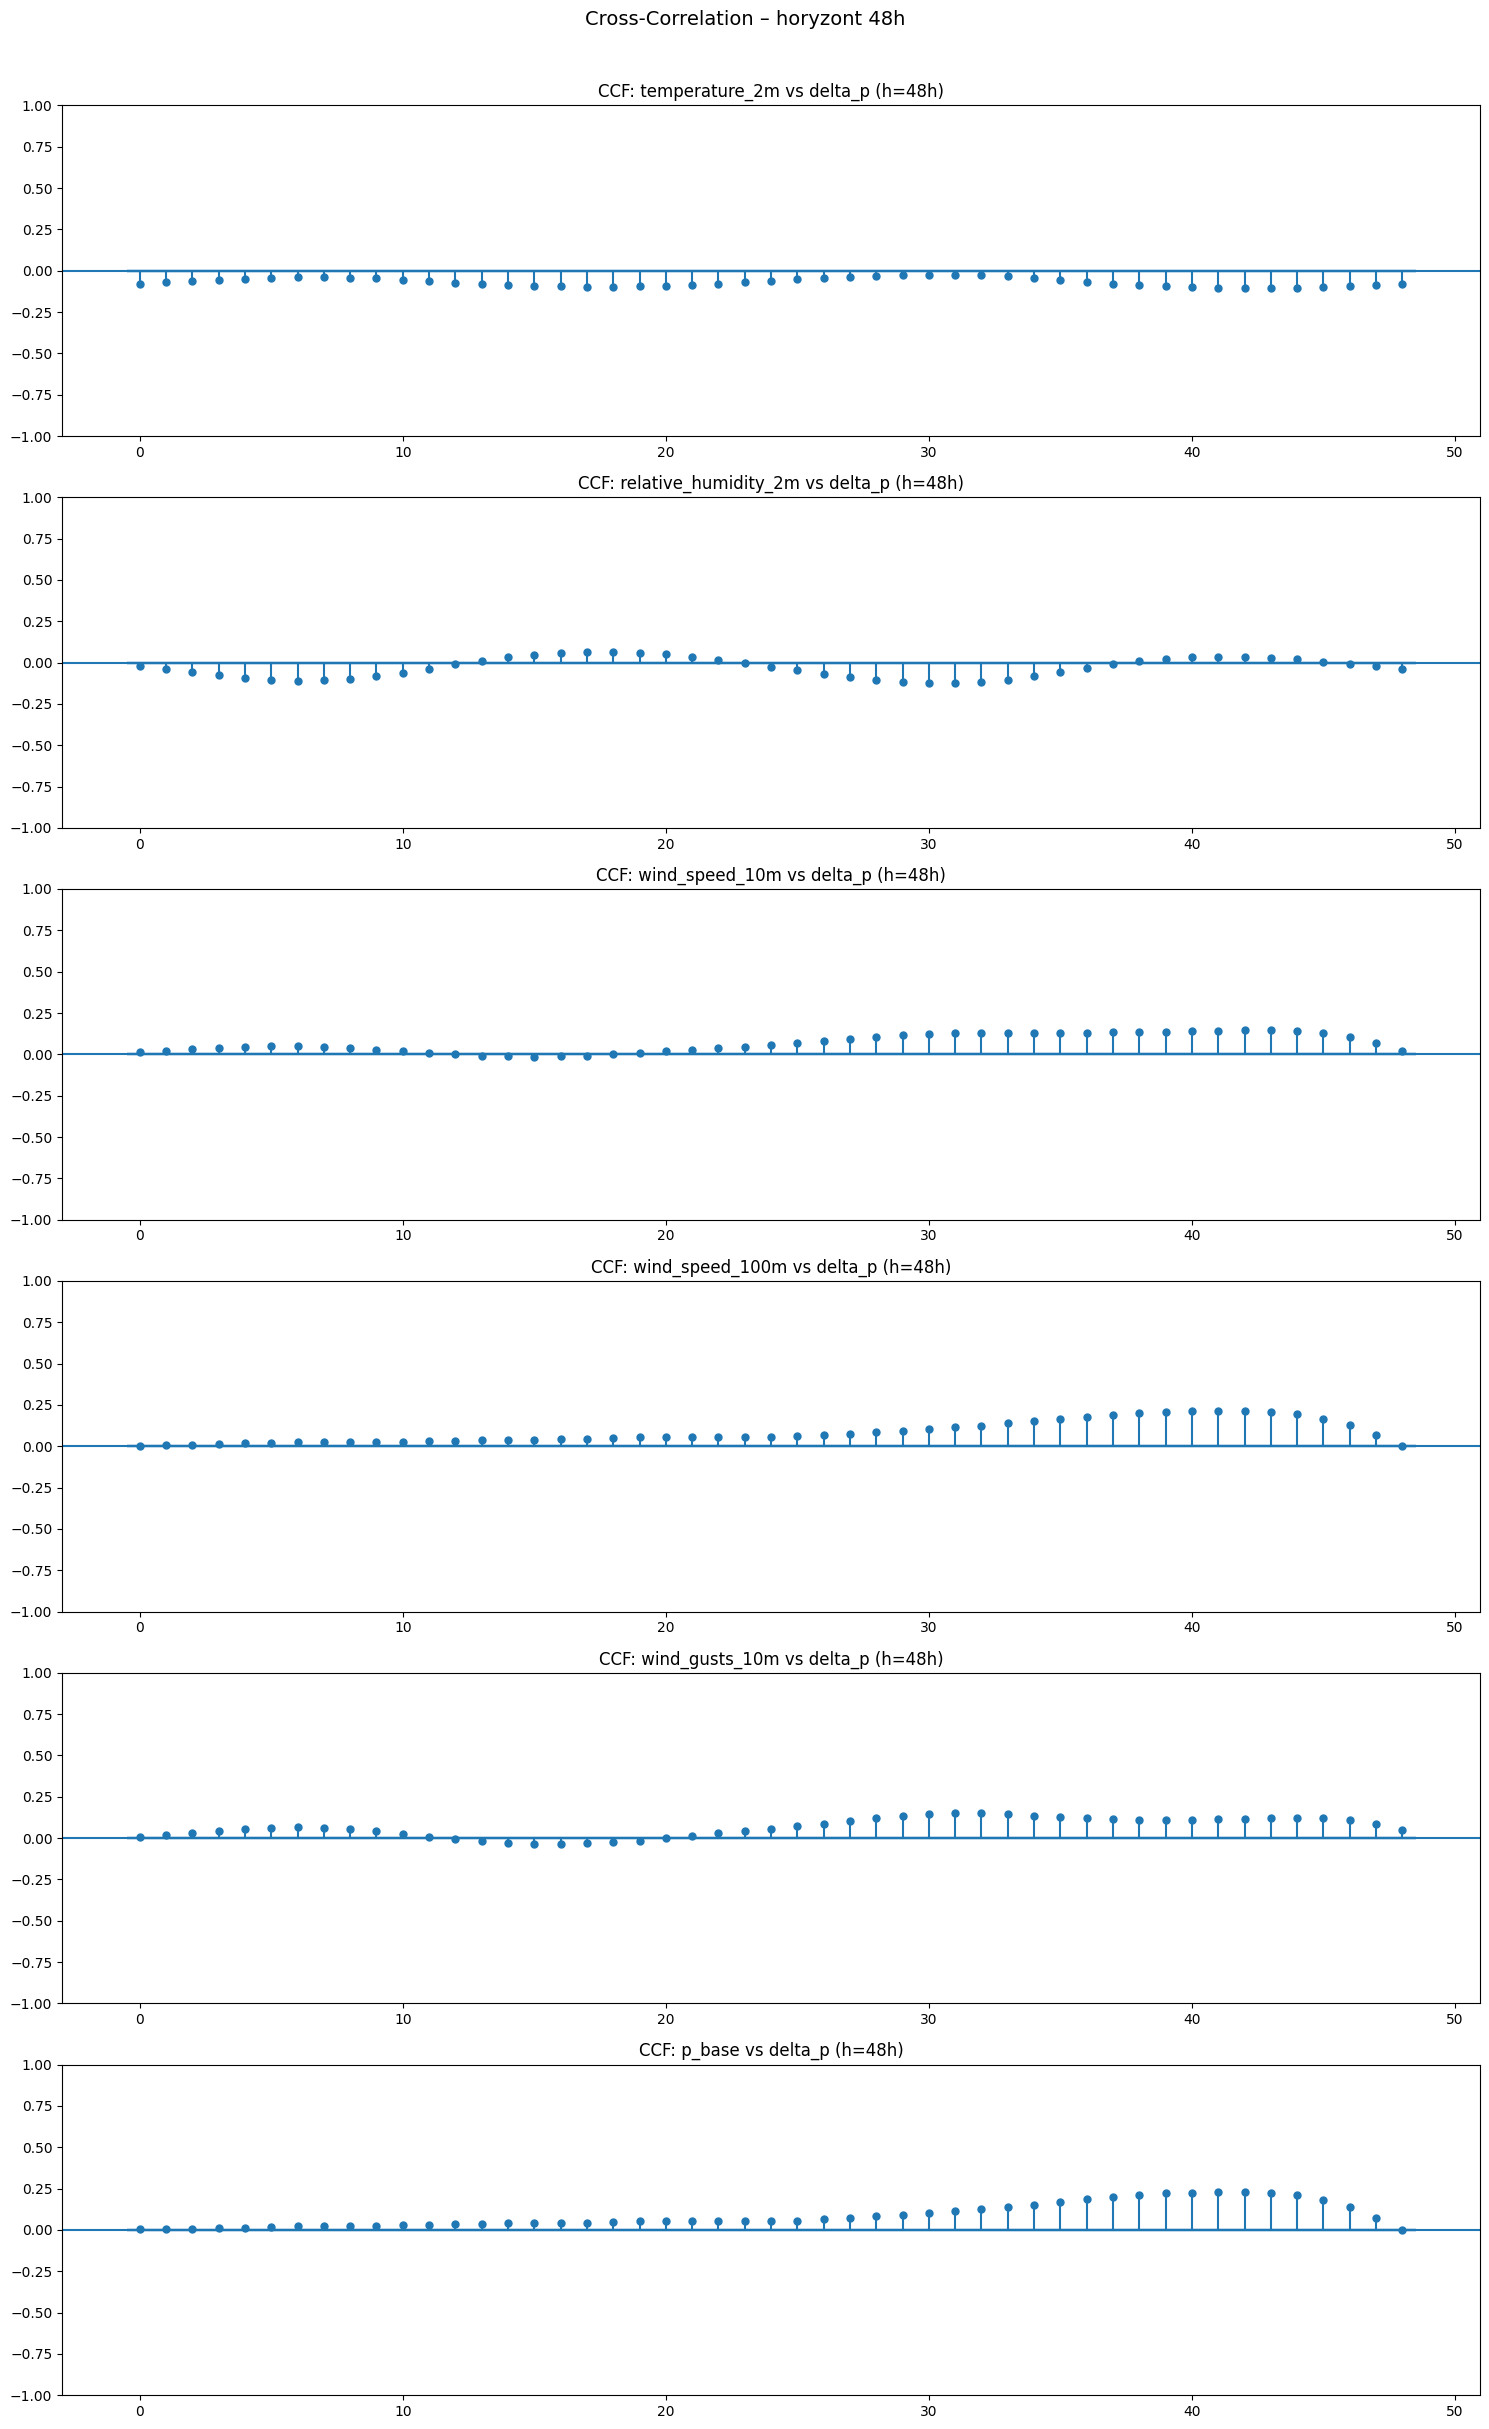

In [37]:
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import ccf
from statsmodels.graphics.tsaplots import plot_ccf

FEATURES = ['temperature_2m', 'relative_humidity_2m',
            'dew_point_2m', 'wind_speed_10m',
            'wind_speed_100m', 'wind_gusts_10m',
            'wind_sin_10m', 'wind_cos_10m',
            'wind_sin_100m', 'wind_cos_100m',
            'p_base']
THRESHOLD = 0.1
LAGS = 48
HORIZONS = [1, 24, 48]

for horizon in HORIZONS:
    target_h = df['delta_p'].shift(-horizon).dropna()
    df_aligned = df.iloc[:len(target_h)]  # wyrównaj długość po dropna

    significant_features = []
    for c in FEATURES:
        corr = ccf(df_aligned[c], target_h)[:LAGS+1]
        if any(abs(corr) > THRESHOLD):
            significant_features.append(c)

    if not significant_features:
        print(f"h={horizon}h: brak znaczących featurów")
        continue

    print(f"h={horizon}h: {significant_features}")

    fig, axes = plt.subplots(len(significant_features), 1,
                             figsize=(15, len(significant_features) * 4))
    
    # gdy tylko jeden feature axes nie jest listą
    if len(significant_features) == 1:
        axes = [axes]

    for idx, feature in enumerate(significant_features):
        plot_ccf(df_aligned[feature], target_h, lags=LAGS, ax=axes[idx])
        axes[idx].set_title(f"CCF: {feature} vs delta_p (h={horizon}h)")

    plt.suptitle(f"Cross-Correlation – horyzont {horizon}h", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.show()